# 02 · Statistical rigour: which findings survive scrutiny?

**Project 03: The Attrition Blindspot** (IBM HR Analytics, synthetic data)

The dashboard shows rates. This notebook asks the harder question: **how much of each headline is signal and how much
could be noise?** Every claim in the README gets a confidence interval, a test and a verdict.

| Tool | Used for | Why |
|---|---|---|
| Wilson interval | A single rate, for example 23 of 65 | Reliable at small n, unlike the simple +/- 1.96 SE interval |
| Newcombe hybrid-score interval | Difference between two rates | Built on Wilson intervals, stays inside the possible range |
| Fisher exact test (and chi-square) | 2x2 comparisons | Several groups have fewer than 100 people |
| Odds ratio (Woolf interval) | Effect size on a ratio scale | Comparable across groups with different baselines |
| Benjamini-Hochberg FDR | The whole family of tests | Many tests means some "significant" results appear by chance |
| Bootstrap | Cross-check on the analytic interval | Two methods that agree are more trustworthy |
| Minimum detectable difference | "How big a gap could this sample even see?" | A non-significant result is only meaningful relative to power |
| Logistic regression with interaction | The performance-paradox claim | Tests whether overtime hurts high performers *more* than others |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from attrition.data import load_clean, repo_root
from attrition.score import add_score
from attrition.stats import (
    bootstrap_diff_ci, compare, comparison_table, driver_table,
    interaction_test, minimum_detectable_difference, wilson_ci,
)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
df = add_score(load_clean())
print(f"{len(df):,} employees, {df['attrition_flag'].sum()} leavers ({100 * df['attrition_flag'].mean():.1f}%)")

1,470 employees, 237 leavers (16.1%)


## 1. Every candidate driver, tested the same way
`diff_pp` is the attrition gap in percentage points (flag present minus flag absent), with a 95% interval.
`q_bh` is the p-value after correcting for testing seven drivers at once.

In [2]:
drivers = {
    "Overtime": "overtime_flag",
    "New manager (0 yrs)": "new_manager_flag",
    "No stock options": "no_stock_options_flag",
    "Lowest job satisfaction (1)": "low_job_satisfaction_flag",
    "Pay below job-level median": "below_level_median_pay_flag",
    "High performer (rating 4)": "high_performer_flag",
    "Promotion gap 3+ yrs": "promo_stagnation_flag",
}
dt = driver_table(df, drivers)
cols = ["label", "n_exposed", "rate_exposed", "rate_reference", "diff_pp",
        "diff_ci_low_pp", "diff_ci_high_pp", "odds_ratio", "p_fisher", "q_bh", "significant_after_fdr"]
dt[cols].round(3)

,label,n_exposed,rate_exposed,rate_reference,diff_pp,diff_ci_low_pp,diff_ci_high_pp,odds_ratio,p_fisher,q_bh,significant_after_fdr
0,Overtime,416,0.305,0.104,20.092,15.416,24.986,3.771,0.000,0.000,True
1,New manager (0 yrs),263,0.323,0.126,19.726,14.006,25.854,3.314,0.000,0.000,True
2,No stock options,631,0.244,0.099,14.513,10.634,18.467,2.941,0.000,0.000,True
3,Lowest job satisfaction (1),289,0.228,0.145,8.358,3.415,13.870,1.748,0.001,0.002,True
4,Pay below job-level median,733,0.184,0.138,4.578,0.816,8.336,1.405,0.019,0.027,True
5,High performer (rating 4),226,0.164,0.161,0.295,-4.470,6.011,1.022,0.922,0.922,False
6,Promotion gap 3+ yrs,373,0.137,0.170,-3.282,-7.178,1.113,0.776,0.143,0.167,False


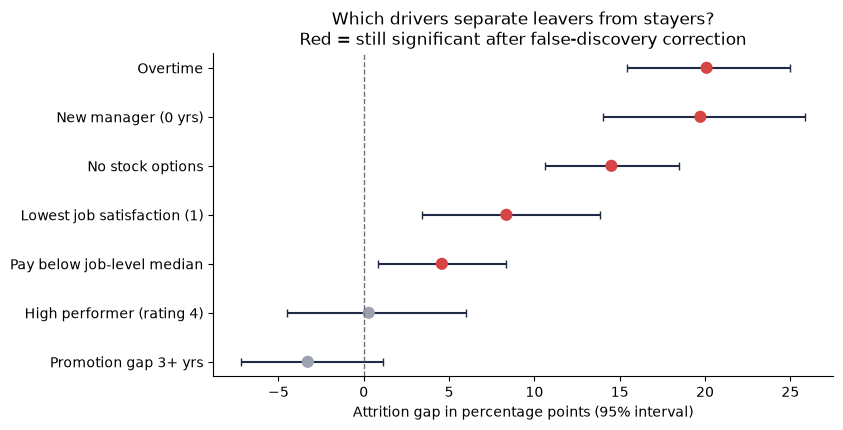

In [3]:
plot = dt.sort_values("diff_pp")
fig, ax = plt.subplots(figsize=(8, 4.2))
colours = np.where(plot["significant_after_fdr"], "#D64545", "#9CA3AF")
ax.errorbar(plot["diff_pp"], range(len(plot)),
            xerr=[plot["diff_pp"] - plot["diff_ci_low_pp"], plot["diff_ci_high_pp"] - plot["diff_pp"]],
            fmt="none", ecolor="#1F2A44", capsize=3, zorder=1)
ax.scatter(plot["diff_pp"], range(len(plot)), c=colours, s=60, zorder=2)
ax.axvline(0, color="#6B7280", linestyle="--", linewidth=1)
ax.set_yticks(range(len(plot)))
ax.set_yticklabels(plot["label"])
ax.set_xlabel("Attrition gap in percentage points (95% interval)")
ax.set_title("Which drivers separate leavers from stayers?\nRed = still significant after false-discovery correction")
ax.spines[["top", "right"]].set_visible(False)
fig_dir = repo_root() / "reports" / "figures"; fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "02_driver_forest_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Claim: "a performance rating carries no attrition signal"
A non-significant result can mean "no effect" or "not enough people to see one". We check both.

In [4]:
hp = df["high_performer_flag"] == 1
rating = compare(df, hp, ~hp, "High performer vs everyone else")
print(f"High performers: {rating.rate_exposed:.1%} ({rating.leavers_exposed}/{rating.n_exposed})   "
      f"Others: {rating.rate_reference:.1%} ({rating.leavers_reference}/{rating.n_reference})")
print(f"Gap: {rating.diff_pp:+.1f} points, 95% CI [{rating.diff_ci_low_pp:+.1f}, {rating.diff_ci_high_pp:+.1f}], "
      f"Fisher p = {rating.p_fisher:.2f}")

boot = bootstrap_diff_ci(df.loc[hp, "attrition_flag"].to_numpy(), df.loc[~hp, "attrition_flag"].to_numpy())
print(f"Bootstrap 95% CI (10,000 resamples): [{boot[0]:+.1f}, {boot[1]:+.1f}]  <- agrees with the analytic interval")

mdd = minimum_detectable_difference(rating.rate_reference, rating.n_exposed, rating.n_reference)
print(f"Minimum detectable gap (80% power): about {mdd:.1f} points")

High performers: 16.4% (37/226)   Others: 16.1% (200/1244)
Gap: +0.3 points, 95% CI [-4.5, +6.0], Fisher p = 0.92


Bootstrap 95% CI (10,000 resamples): [-4.8, +5.6]  <- agrees with the analytic interval
Minimum detectable gap (80% power): about 8.1 points


## 3. Claim: "the rating hides a workload split" (the performance paradox)
Overtime clearly raises attrition for everyone. The paradox claim is narrower: that overtime hurts **high performers more**.
That is an *interaction*, so it needs its own test.

In [5]:
ot = df["overtime_flag"] == 1
parts = [
    compare(df, hp & ~ot, ~hp & ~ot, "No overtime: high performer vs others"),
    compare(df, hp & ot, ~hp & ot, "Overtime: high performer vs others"),
    compare(df, hp & ot, hp & ~ot, "Within high performers: overtime vs none"),
    compare(df, ~hp & ot, ~hp & ~ot, "Within other staff: overtime vs none"),
]
pd.DataFrame([vars(p) for p in parts])[
    ["label", "n_exposed", "rate_exposed", "n_reference", "rate_reference",
     "diff_pp", "diff_ci_low_pp", "diff_ci_high_pp", "p_fisher"]].round(3)

,label,n_exposed,rate_exposed,n_reference,rate_reference,diff_pp,diff_ci_low_pp,diff_ci_high_pp,p_fisher
0,No overtime: high performer vs others,161,0.087,893,0.108,-2.055,-6.144,3.631,0.486
1,Overtime: high performer vs others,65,0.354,351,0.296,5.755,-5.873,18.715,0.380
2,Within high performers: overtime vs none,65,0.354,161,0.087,26.689,14.887,39.309,0.000
3,Within other staff: overtime vs none,351,0.296,893,0.108,18.879,13.837,24.194,0.000


In [6]:
inter = interaction_test(df, "high_performer_flag", "overtime_flag")
print(f"Interaction odds ratio: {inter['interaction_odds_ratio']:.2f}  "
      f"95% CI [{inter['or_ci_low']:.2f}, {inter['or_ci_high']:.2f}]   p = {inter['p_value']:.3f}")
print("-> an odds ratio of 1 means 'overtime affects both groups equally'; the interval contains 1"
      if inter["or_ci_low"] < 1 < inter["or_ci_high"] else "-> the interval excludes 1")

Interaction odds ratio: 1.64  95% CI [0.73, 3.70]   p = 0.229
-> an odds ratio of 1 means 'overtime affects both groups equally'; the interval contains 1


## 4. Claim: "the new-manager effect is mostly a first-year-employee effect"

In [7]:
first_year = df["years_at_company"] <= 1
new_mgr = df["new_manager_flag"] == 1
decomp = [
    compare(df, first_year, ~first_year, "First-year employees vs established"),
    compare(df, ~first_year & new_mgr, ~first_year & ~new_mgr, "Established: new manager vs same manager"),
]
pd.DataFrame([vars(d) for d in decomp])[
    ["label", "n_exposed", "leavers_exposed", "rate_exposed", "n_reference", "rate_reference",
     "diff_pp", "diff_ci_low_pp", "diff_ci_high_pp", "p_fisher"]].round(3)

,label,n_exposed,leavers_exposed,rate_exposed,n_reference,rate_reference,diff_pp,diff_ci_low_pp,diff_ci_high_pp,p_fisher
0,First-year employees vs established,215,75,0.349,1255,0.129,21.975,15.609,28.787,0.000
1,Established: new manager vs same manager,61,14,0.230,1194,0.124,10.556,1.575,22.645,0.028


## 5. Small cells: how uncertain is each headline rate? (Wilson 95% intervals)

In [8]:
cells = {
    "High performers, no overtime": (df[hp & ~ot]["attrition_flag"].sum(), (hp & ~ot).sum()),
    "High performers, overtime": (df[hp & ot]["attrition_flag"].sum(), (hp & ot).sum()),
    "Overtime + new manager": (df[ot & new_mgr]["attrition_flag"].sum(), (ot & new_mgr).sum()),
    "First-year employees": (df[first_year]["attrition_flag"].sum(), first_year.sum()),
    "Established, new manager": (df[~first_year & new_mgr]["attrition_flag"].sum(), (~first_year & new_mgr).sum()),
    "Critical band": (df[df["risk_band"] == "Critical"]["attrition_flag"].sum(), (df["risk_band"] == "Critical").sum()),
    "Low band": (df[df["risk_band"] == "Low"]["attrition_flag"].sum(), (df["risk_band"] == "Low").sum()),
}
rows = []
for name, (x, n) in cells.items():
    lo, hi = wilson_ci(int(x), int(n))
    rows.append({"group": name, "leavers": int(x), "n": int(n), "rate": x / n, "ci_low": lo, "ci_high": hi,
                 "ci_width_pts": 100 * (hi - lo)})
cell_table = pd.DataFrame(rows)
cell_table.round(3)

,group,leavers,n,rate,ci_low,ci_high,ci_width_pts
0,"High performers, no overtime",14,161,0.087,0.053,0.141,8.816
1,"High performers, overtime",23,65,0.354,0.249,0.475,22.649
2,Overtime + new manager,43,82,0.524,0.418,0.629,21.130
3,First-year employees,75,215,0.349,0.288,0.415,12.640
4,"Established, new manager",14,61,0.230,0.142,0.349,20.720
5,Critical band,64,125,0.512,0.425,0.598,17.262
6,Low band,25,516,0.048,0.033,0.071,3.751


## 6. Claims register: one table for the whole README

In [9]:
comparisons = [
    compare(df, hp, ~hp, "Rating: high performer vs others"),
    compare(df, ot, ~ot, "Overtime vs no overtime"),
    compare(df, hp & ~ot, ~hp & ~ot, "No overtime: high performer vs others"),
    compare(df, hp & ot, ~hp & ot, "Overtime: high performer vs others"),
    compare(df, hp & ot, hp & ~ot, "High performers: overtime vs none"),
    compare(df, ~hp & ot, ~hp & ~ot, "Other staff: overtime vs none"),
    compare(df, ot & new_mgr, ~(ot & new_mgr), "Overtime + new manager vs everyone else"),
    compare(df, first_year, ~first_year, "First-year vs established"),
    compare(df, ~first_year & new_mgr, ~first_year & ~new_mgr, "Established: new vs same manager"),
    compare(df, df["promo_stagnation_flag"] == 1, df["promo_stagnation_flag"] == 0, "Promotion gap 3+ yrs vs less"),
    compare(df, df["risk_band"] == "Critical", df["risk_band"] == "Low", "Critical band vs Low band (in-sample)"),
]
register = comparison_table(comparisons)
register["verdict"] = np.where(register["significant_after_fdr"], "Supported",
                               "Not distinguishable from zero")
show = register[["label", "rate_exposed", "rate_reference", "diff_pp", "diff_ci_low_pp",
                 "diff_ci_high_pp", "p_fisher", "q_bh", "verdict"]].round(3)
tables_dir = repo_root() / "reports" / "tables"; tables_dir.mkdir(parents=True, exist_ok=True)
show.to_csv(tables_dir / "02_claims_register.csv", index=False)
show

,label,rate_exposed,rate_reference,diff_pp,diff_ci_low_pp,diff_ci_high_pp,p_fisher,q_bh,verdict
0,Rating: high performer vs others,0.164,0.161,0.295,-4.470,6.011,0.922,0.922,Not distinguishable from zero
1,Overtime vs no overtime,0.305,0.104,20.092,15.416,24.986,0.000,0.000,Supported
2,No overtime: high performer vs others,0.087,0.108,-2.055,-6.144,3.631,0.486,0.535,Not distinguishable from zero
3,Overtime: high performer vs others,0.354,0.296,5.755,-5.873,18.715,0.380,0.465,Not distinguishable from zero
4,High performers: overtime vs none,0.354,0.087,26.689,14.887,39.309,0.000,0.000,Supported
5,Other staff: overtime vs none,0.296,0.108,18.879,13.837,24.194,0.000,0.000,Supported
6,Overtime + new manager vs everyone else,0.524,0.140,38.462,27.616,49.059,0.000,0.000,Supported
7,First-year vs established,0.349,0.129,21.975,15.609,28.787,0.000,0.000,Supported
8,Established: new vs same manager,0.230,0.124,10.556,1.575,22.645,0.028,0.045,Supported
9,Promotion gap 3+ yrs vs less,0.137,0.170,-3.282,-7.178,1.113,0.143,0.197,Not distinguishable from zero
